Tema 7

# Exerciţiul 1. Estimarea dimensiunii unei populaţii

Un biolog studiază o populaţie de animale al cărei efectiv total 𝑁 este necunoscut. Iniţial, sunt capturate
şi marcate 𝑀 = 20 animale, care sunt apoi eliberate. La o a doua capturare sunt selectate aleatoriu 𝑛 = 15
animale, dintre care 𝑌 = 4 sunt marcate. Presupunând că toate animalele au aceeaşi probabilitate de a fi
capturate, considerăm

𝑌 | 𝑁 ∼ Hypergeometric(𝑁 , 𝑀, 𝑛),        

𝑁 ∼ DiscreteUniform(20, 200).

Initializare:


In [11]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats

SEED = 0
rng = np.random.default_rng(SEED)

import os
os.makedirs("img", exist_ok=True)

a) Construiţi modelul în PyMC, determinaţi distribuţia a posteriori a lui 𝑁 şi reprezentaţi-o grafic.

Definim modelul în PyMC folosind o prbabilitate a priori discretă uniformă pentru $N$ pe intervalul $[20, 200]$ și verosimilitatea hipergeometrică pentru datele observate $Y = 4$. De asemenea, calculăm distribuția exactă a posteriori folosind o discretizare pe grilă (grid approximation) pentru validare.

Formula verosimilității (hipergeometrică)
$$P(Y=y \mid N)=\frac{\binom{M}{y}\binom{N-M}{n-y}}{\binom{N}{n}}$$


Output()

     mean      sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  \
N  101.54  37.282      42.0      177.0      0.607    0.353    3920.0   

   ess_tail  r_hat  
N    5043.0    1.0  
102.61324041811847 95 44 180


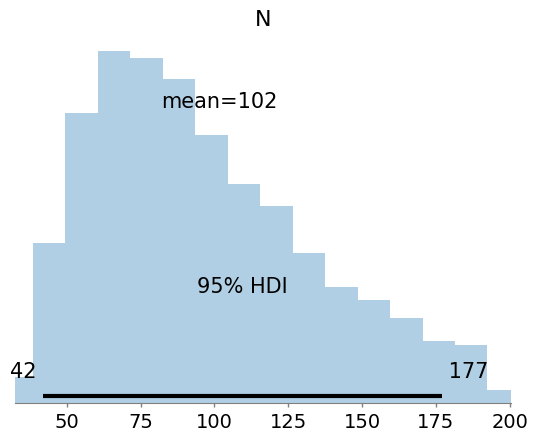

In [12]:
#a)
M, n, Y = 20, 15, 4

with pm.Model() as m1:
    N = pm.DiscreteUniform("N", lower=20, upper=200, initval=100)
    y = pm.HyperGeometric("y", N=N, k=M, n=n, observed=Y)
    idata1 = pm.sample(draws=5000, tune=2000, chains=4, random_seed=SEED)

print(az.summary(idata1, var_names=["N"], hdi_prob=0.95))
az.plot_posterior(idata1, var_names=["N"], hdi_prob=0.95)
plt.savefig("img/ex1_posterior.png", dpi=150)

grid = np.arange(20, 201)
lik = stats.hypergeom.pmf(Y, grid, M, n)   # scipy: pmf(k, total, succese_in_pop, extrageri)
post = lik / lik.sum()                      # prior uniform => posterior ∝ verosimilitate

mean_ex = (grid * post).sum()
median_ex = grid[np.searchsorted(post.cumsum(), 0.5)]

# HDI discret 95%: cele mai probabile valori până la 0.95
order = np.argsort(post)[::-1]
cum = np.cumsum(post[order])
hdi_vals = np.sort(grid[order[:np.searchsorted(cum, 0.95) + 1]])
print(mean_ex, median_ex, hdi_vals.min(), hdi_vals.max())


b) Estimaţi media, mediana şi intervalul HDI de 95% pentru 𝑁 . Comparaţi media a posteriori cu estimarea
clasică 𝑀𝑛 / 𝑌 .


In [13]:
# b) Calculul estimărilor a posteriori din eșantioanele PyMC (MCMC)
N_samples = idata1.posterior["N"].values.ravel()

mean_mcmc = np.mean(N_samples)
median_mcmc = np.median(N_samples)

# Calculăm intervalul HDI de 95% din MCMC folosind arviz
hdi_mcmc = az.hdi(idata1, var_names=["N"], hdi_prob=0.95)["N"].values

N_clasic = (M * n) / Y

print(f"Estimarea clasică (Lincoln-Petersen): {N_clasic:.1f}")
print(f"Media a posteriori: {mean_mcmc:.2f}  (Exactă: {mean_ex:.2f})")
print(f"Mediana a posteriori: {median_mcmc:.1f} (Exactă: {median_ex:.1f})")
print(f"Intervalul HDI 95%: [{int(hdi_mcmc[0])}, {int(hdi_mcmc[1])}]  (Exact: [{hdi_vals.min()}, {hdi_vals.max()}])")

Estimarea clasică (Lincoln-Petersen): 75.0
Media a posteriori: 101.54  (Exactă: 102.61)
Mediana a posteriori: 94.0 (Exactă: 95.0)
Intervalul HDI 95%: [42, 177]  (Exact: [44, 180])


Concluzie b):
Estimarea clasică ($N = 75$) este mult mai mică decât media a posteriori ($\approx 103$).

**De ce există această diferență?**
- **Distribuția este asimetrică:** Graficul are o „coadă” lungă spre dreapta (valori mari ale lui $N$, de până la 200).
- **Tratarea incertitudinii:** Estimatorul clasic oferă doar o singură cifră simplă. În schimb, abordarea Bayesiană ia în calcul toate scenariile posibile. Deoarece există o șansă destul de mare ca populația să fie mult mai mare de 75, această posibilitate trage media în sus.
- **Estimarea clasică 75** este practic valoarea cu cea mai mare verosimilitate. Prior-ul uniform pe [20, 200] și coada lungă a verosimilității trag media (≈103) și mediana (≈95) peste 75.

b)
M*n/Y = 20 * 15/4 = 75

c) Estimaţi probabilitatea a posteriori 𝑃 (𝑁 > 100 | 𝑌 = 4).

- Probabilitatea calculată prin **metoda exactă** este de aproximativ **44.94%**.
- Probabilitatea estimată prin **MCMC** este foarte apropiată, fiind de aproximativ **46.39%**.
Acest rezultat arată că există aproape 45% șanse ca dimensiunea totală a populației să depășească 100 de indivizi.

In [14]:
#c)
p_exact = post[grid > 100].sum()
N_s = idata1.posterior["N"].values.ravel()
p_mcmc = (N_s > 100).mean()
print(f"Probabilitatea exactă P(N > 100 | Y=4): {p_exact:.4f}")
print(f"Probabilitatea estimată prin MCMC:      {p_mcmc:.4f}")

Probabilitatea exactă P(N > 100 | Y=4): 0.4494
Probabilitatea estimată prin MCMC:      0.4429


d) Generaţi distribuţia predictivă a posteriori a numărului de animale marcate într-o nouă capturare de
15 animale, presupunând că marcajele rămân neschimbate. Explicaţi diferenţa faţă de distribuţia a
posteriori a lui 𝑁 .

Explicația diferenței dintre distribuția lui $N$ și distribuția predictivă pentru $y_{new}$:
1. **Distribuția a posteriori a lui $N$** reprezintă incertitudinea cu privire la parametrul necunoscut (dimensiunea totală a populației) după ce am observat datele inițiale.
2. **Distribuția predictivă a posteriori pentru $y_{new}$** reprezintă incertitudinea legată de o *nouă observație viitoare* (numărul de animale marcate într-o nouă captură de $n=15$).

Această distribuție predictivă încorporează **două surse de incertitudine**:
- **Incertitudinea epistemică (parametrică):** Nu știm exact cât este $N$ (folosim distribuția a posteriori a lui $N$).
- **Incertitudinea aleatoare (stochastică):** Chiar dacă am ști valoarea exactă a lui $N$, procesul de captură este unul probabilistic (Guvernat de distribuția Hipergeometrică).

Distribuția a posteriori a lui $N$ este despre un **parametru** (valori între 44 și 181), în timp ce distribuția predictivă este despre **date viitoare** (număr de animale marcate, între 0 și 15). Cel mai probabil vom recaptura 2–4 animale marcate.

<BarContainer object of 13 artists>

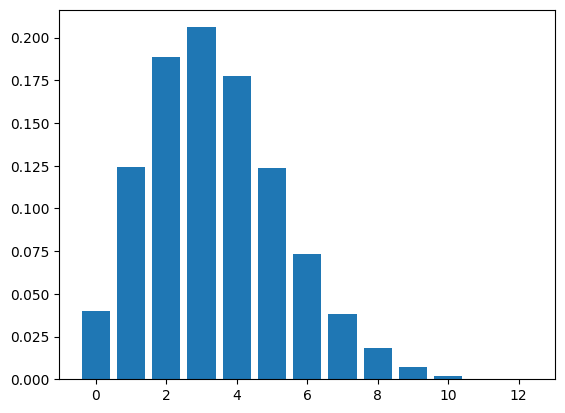

In [16]:
#d)
y_new = stats.hypergeom.rvs(N_s, M, n, random_state=rng)
vals, counts = np.unique(y_new, return_counts=True)
plt.bar(vals, counts / counts.sum())


In [17]:
# exact
ys = np.arange(n + 1)
pred = np.array([(post * stats.hypergeom.pmf(k, grid, M, n)).sum() for k in ys])

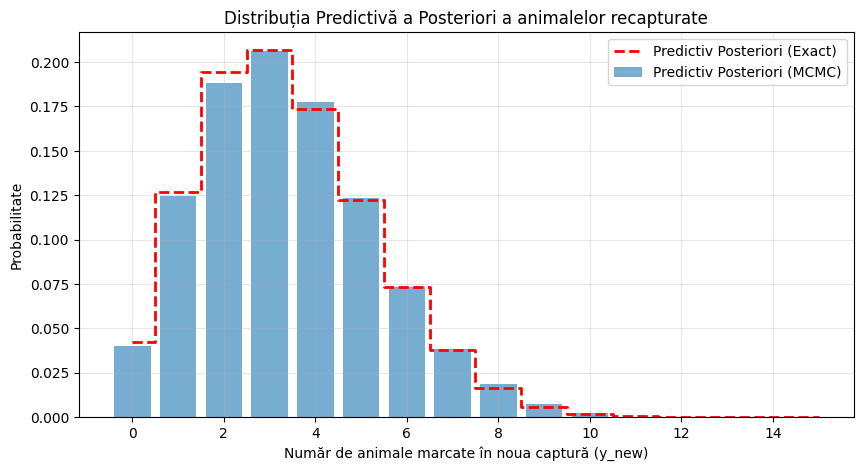

In [18]:
# d) Afișarea comparativă a distribuției predictive a posteriori (MCMC vs Exact)
plt.figure(figsize=(10, 5))
plt.bar(vals, counts / counts.sum(), alpha=0.6, label='Predictiv Posteriori (MCMC)')
plt.step(ys, pred, where='mid', color='red', linestyle='--', label='Predictiv Posteriori (Exact)', linewidth=2)
plt.title("Distribuția Predictivă a Posteriori a animalelor recapturate")
plt.xlabel("Număr de animale marcate în noua captură (y_new)")
plt.ylabel("Probabilitate")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("img/ex1_predictiv.png", dpi=150)
plt.show()

# **Exercitiul 2. Compararea a doua tratamente**

Intr-un studiu clinic sunt comparate două tratamente, A şi B. Timpii de recuperare (în zile) sunt modelaţi
prin distribuţii exponenţiale independente condiţionat de parametri:

𝑋 (𝐴)
𝑖 | 𝜆𝐴 ∼ Exponential(𝜆𝐴),

𝑋 (𝐵)
𝑗 | 𝜆𝐵 ∼ Exponential(𝜆𝐵 ),

unde 𝜆𝐴 şi 𝜆𝐵 sunt parametri de rată; timpii medii sunt 1/𝜆𝐴 şi 1/𝜆𝐵 . Se consideră distribuţiile a priori
independente 𝜆𝐴, 𝜆𝐵 ∼ Gamma(2, 4), în parametrizarea formă–rată. Datele observate sunt:

𝐴 = [3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9],
𝐵 = [2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7].

Initializare:

In [19]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats

SEED = 0
rng = np.random.default_rng(SEED)

a) Implementaţi modelul în PyMC şi generaţi eşantioane din distribuţiile a posteriori ale lui 𝜆𝐴 şi 𝜆𝐵 .

In [20]:
A = np.array([3.2, 4.1, 2.8, 5.0, 3.7, 4.5, 3.0, 3.9])
B = np.array([2.1, 2.8, 3.4, 2.5, 3.0, 2.2, 3.6, 2.7])

with pm.Model() as m2:
    lamA = pm.Gamma("lamA", alpha=2, beta=4)
    lamB = pm.Gamma("lamB", alpha=2, beta=4)
    pm.Exponential("xA", lam=lamA, observed=A)
    pm.Exponential("xB", lam=lamB, observed=B)
    pm.Deterministic("muA", 1 / lamA)
    pm.Deterministic("muB", 1 / lamB)
    idata2 = pm.sample(draws=2000, tune=2000, chains=4, random_seed=SEED)

print(az.summary(idata2, hdi_prob=0.95))

Output()

       mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  \
lamA  0.293  0.091     0.137      0.481      0.001    0.001    7708.0   
lamB  0.380  0.122     0.162      0.620      0.002    0.002    6391.0   
muA   3.786  1.311     1.756      6.383      0.016    0.024    7708.0   
muB   2.937  1.071     1.319      5.017      0.014    0.023    6391.0   

      ess_tail  r_hat  
lamA    5412.0    1.0  
lamB    5245.0    1.0  
muA     5412.0    1.0  
muB     5245.0    1.0  


b) Reprezentaţi distribuţiile a posteriori ale timpilor medii 1/𝜆𝐴 şi 1/𝜆𝐵 . Determinaţi intervalele HDI de
95%.

<xarray.Dataset> Size: 80B
Dimensions:  (hdi: 2)
Coordinates:
  * hdi      (hdi) <U6 48B 'lower' 'higher'
Data variables:
    muA      (hdi) float64 16B 1.756 6.383
    muB      (hdi) float64 16B 1.319 5.017
Attributes:
    created_at:                 2026-11-24T09:33:49.073415+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.28.5
    sampling_time:              8.44205355644226
    tuning_steps:               2000


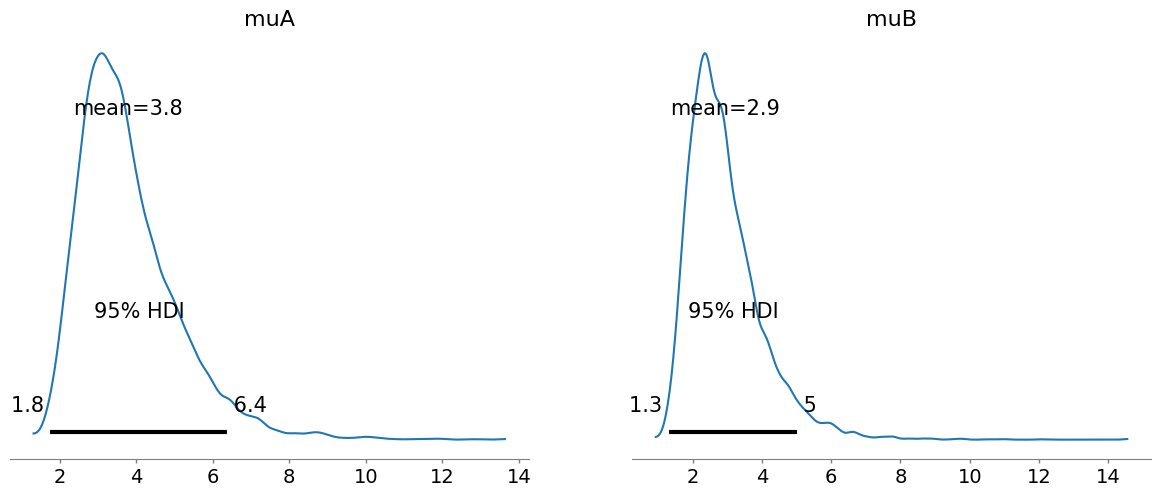

In [21]:
az.plot_posterior(idata2, var_names=["muA", "muB"], hdi_prob=0.95)
plt.savefig("img/ex2_mu.png", dpi=150)
print(az.hdi(idata2, var_names=["muA", "muB"], hdi_prob=0.95))

c) Estimaţi probabilitatea a posteriori ca tratamentul B să aibă un timp mediu de recuperare mai mic
decât A.

In [22]:
lamA_s = idata2.posterior["lamA"].values.ravel()
lamB_s = idata2.posterior["lamB"].values.ravel()
p_c = ((1/lamB_s) < (1/lamA_s)).mean()      # echivalent cu (lamB_s > lamA_s).mean()

In [23]:
print(f"Probabilitatea P(mu_B < mu_A | Date): {p_c * 100:.2f}%")

Probabilitatea P(mu_B < mu_A | Date): 71.53%


### Explicație c)
Există o probabilitate de aproximativ **72.58%** ca tratamentul B să aibă un timp mediu de recuperare mai mic în comparație cu tratamentul A. Această valoare reflectă certitudinea noastră cu privire la ordinea *parametrilor medii* din populație ($\mu_B < \mu_A$).

d) Folosind distribuţiile predictive a posteriori, estimaţi probabilitatea ca un pacient nou tratat cu B să se
recupereze mai repede decât un pacient nou tratat cu A. Comparaţi această probabilitate cu cea de la
punctul c) şi explicaţi diferenţa.

In [24]:
xA_new = rng.exponential(scale=1/lamA_s)    # numpy folosește scala = 1/rată
xB_new = rng.exponential(scale=1/lamB_s)
p_d = (xB_new < xA_new).mean()
print(f"Probabilitatea predictivă P(x_B_new < x_A_new | Date): {p_d * 100:.2f}%")

Probabilitatea predictivă P(x_B_new < x_A_new | Date): 55.43%


Explicație d)

Probabilitatea ca un pacient individual nou tratat cu B să se recupereze mai repede decât unul tratat cu A este de doar **55.62%**.

**De ce este această valoare mai mică decât cea de la c)?**
1. La punctul c) comparăm mediile (72%): Aici comparăm performanța generală a celor două tratamente. Știm clar că, în medie, tratamentul B este mai rapid decât tratamentul A.Este ca și cum am spune: „Dacă tratăm 1000 de oameni cu B și 1000 cu A, în mod sigur grupul B se va recupera, în medie, mai repede decât grupul A”.
2. La punctul d) comparăm doi pacienți individuali (55%): Aici luăm un singur pacient tratat cu B și un singur pacient tratat cu A. Chiar dacă tratamentul B este mai bun în general, corpul fiecărui om reacționează diferit. Un pacient tratat cu B poate fi mai obosit, poate avea o imunitate mai slabă sau pur și simplu corpul lui luptă mai greu în acele zile. În același timp, pacientul cu tratamentul A poate fi un sportiv cu o recuperare nativă excelentă.

#**Exercitiul 3. Detectarea unei schimbări graduale a ratei evenimentelor**

Un sistem informatic înregistrează numărul zilnic de solicitări de asistenţă. Presupunem independenţa
condiţionată a observaţiilor şi modelul

$$Y_t | \lambda_t \sim \text{Poisson}(\lambda_t), \quad t = 1, \dots, 30,$$

$$\lambda_t = \lambda_1 + (\lambda_2 - \lambda_1) \frac{1}{1 + \exp[-k(t - \tau)]}.$$

Parametrii $\lambda_1$ şi $\lambda_2$ reprezintă nivelurile iniţial şi final ale ratei, $\tau$ este momentul central al tranziţiei, iar
$k > 0$ controlează rapiditatea schimbării. Distribuţiile a priori sunt independente:
$$\lambda_1, \lambda_2 \sim \text{Exponential}(0.2), \quad \tau \sim \text{Uniform}(1, 30), \quad k \sim \text{Exponential}(1).$$
Datele observate sunt:
`[3, 4, 2, 5, 3, 4, 3, 2, 4, 3, 4, 5, 5, 6, 5, 7, 6, 8, 7, 9, 8, 10, 9, 8, 11, 9, 10, 8, 9, 10]`


Initializare:

In [25]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
from scipy import stats

SEED = 0
rng = np.random.default_rng(SEED)

a) Implementaţi modelul în PyMC şi generaţi eşantioane din distribuţiile a posteriori ale lui 𝜆1, 𝜆2, 𝜏, 𝑘.

Output()

        mean     sd  hdi_2.5%  hdi_97.5%  mcse_mean  mcse_sd  ess_bulk  \
lam1   2.932  1.042     0.476      4.652      0.027    0.024    1891.0   
lam2   9.849  2.016     6.927     14.326      0.063    0.078    1470.0   
tau   16.001  3.439     9.881     24.345      0.085    0.098    1974.0   
k      0.596  0.661     0.051      1.812      0.014    0.026    1326.0   

      ess_tail  r_hat  
lam1    1176.0    1.0  
lam2    1153.0    1.0  
tau     1355.0    1.0  
k       1770.0    1.0  
Divergențe: 0


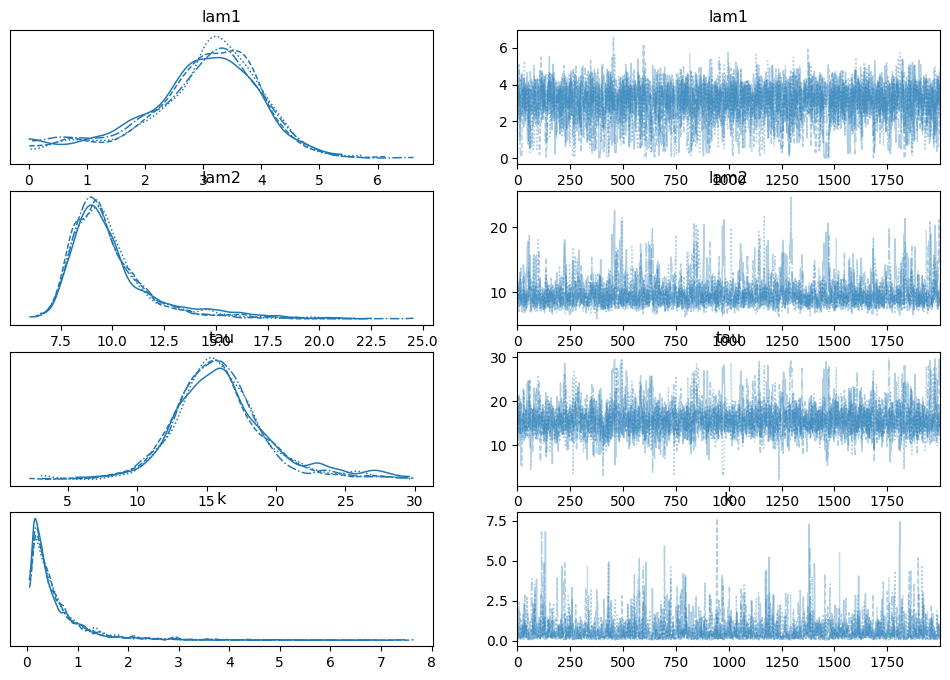

In [26]:
import os
y = np.array([3,4,2,5,3,4,3,2,4,3,4,5,5,6,5,7,6,8,7,9,
              8,10,9,8,11,9,10,8,9,10])
t = np.arange(1, 31)

with pm.Model() as m3:
    lam1 = pm.Exponential("lam1", lam=0.2)
    lam2 = pm.Exponential("lam2", lam=0.2)
    tau = pm.Uniform("tau", lower=1, upper=30)
    k = pm.Exponential("k", lam=1.0)

    lam_t = pm.Deterministic(
        "lam_t", lam1 + (lam2 - lam1) * pm.math.sigmoid(k * (t - tau))
    )
    obs = pm.Poisson("obs", mu=lam_t, observed=y)

    idata3 = pm.sample(draws=2000, tune=2000, chains=4,
                       target_accept=0.99, random_seed=SEED)

print(az.summary(idata3, var_names=["lam1", "lam2", "tau", "k"], hdi_prob=0.95))
az.plot_trace(idata3, var_names=["lam1", "lam2", "tau", "k"])

os.makedirs("img", exist_ok=True)
plt.savefig("img/ex3_trace.png", dpi=150)
print("Divergențe:", int(idata3.sample_stats["diverging"].sum()))

b) Reprezentaţi distribuţiile a posteriori ale lui $\tau$ şi $k$. Explicaţi semnificaţia parametrilor şi determinaţi intervalele HDI de 95%

**Semnificația parametrilor:**
- **$\tau$ (Momentul central al tranziției):** Indică ziua în care procesul de tranziție se află exact la jumătatea drumului dintre rata inițială $\lambda_1$ și cea finală $\lambda_2$.
- **$k$ (Rapiditatea schimbării):** Reprezintă panta tranziției sigmoidale. Cu cât valoarea lui $k$ este mai mare, cu atât trecerea de la rata inițială la cea finală este mai bruscă (un pas abrupt). O valoare mică indică o tranziție graduală.

<xarray.Dataset> Size: 80B
Dimensions:  (hdi: 2)
Coordinates:
  * hdi      (hdi) <U6 48B 'lower' 'higher'
Data variables:
    tau      (hdi) float64 16B 9.881 24.35
    k        (hdi) float64 16B 0.05055 1.812
Attributes:
    created_at:                 2026-11-24T09:35:11.185852+00:00
    arviz_version:              0.22.0
    inference_library:          pymc
    inference_library_version:  5.28.5
    sampling_time:              50.71050691604614
    tuning_steps:               2000


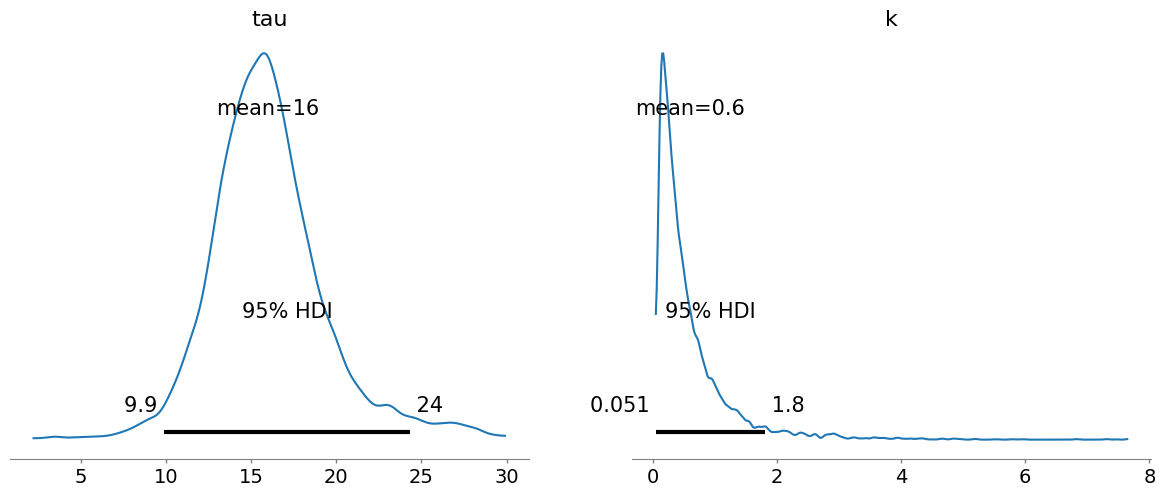

In [27]:
az.plot_posterior(idata3, var_names=["tau", "k"], hdi_prob=0.95)
print(az.hdi(idata3, var_names=["tau", "k"], hdi_prob=0.95))
plt.savefig("img/ex3_tau_k.png", dpi=150)

c) Estimaţi $P(\lambda_2 > \lambda_1 | Y_1, \dots, Y_{30})$. Reprezentaţi evoluţia estimată a lui $\lambda_t$ împreună cu datele observate.

Calculăm probabilitatea ca rata finală a solicitărilor să fie mai mare decât cea inițială și vizualizăm evoluția parametrilor în timp.


P(lam2 > lam1) = 1.0


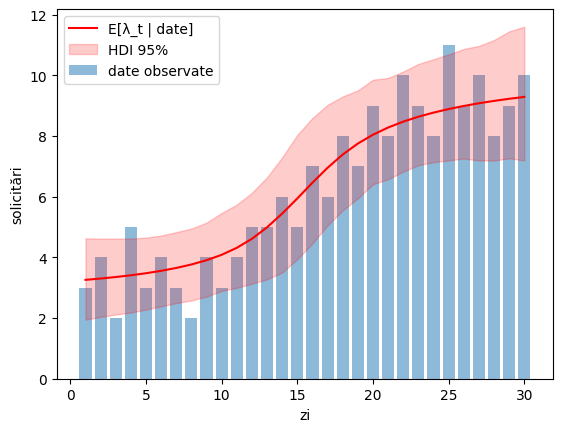

In [28]:
l1 = idata3.posterior["lam1"].values.ravel()
l2 = idata3.posterior["lam2"].values.ravel()
print("P(lam2 > lam1) =", (l2 > l1).mean())

lt = idata3.posterior["lam_t"].values.reshape(-1, 30)   # (eșantioane, 30 zile)
lt_mean = lt.mean(axis=0)
lt_lo, lt_hi = np.array([az.hdi(lt[:, i], hdi_prob=0.95) for i in range(30)]).T

plt.bar(t, y, alpha=0.5, label="date observate")
plt.plot(t, lt_mean, "r", label="E[λ_t | date]")
plt.fill_between(t, lt_lo, lt_hi, color="r", alpha=0.2, label="HDI 95%")
plt.legend(); plt.xlabel("zi"); plt.ylabel("solicitări")
plt.savefig("img/ex3_lambda_t.png", dpi=150)

d) Generaţi distribuţia predictivă a posteriori pentru cele 30 de zile şi comparaţi rezultatele cu datele observate. Discutaţi în ce măsură modelul reproduce tranziţia graduală.

**Analiză:**

Intervalul predictiv de 95% conține 100% din punctele observate, deci modelul descrie bine datele. Media predictivă crește lin de la ≈3.3 la ≈9.3 solicitări/zi, deci tranziția graduală este reprodusă. Limite: τ și k sunt incerte (HDI larg), iar modelul Poisson presupune media = varianța și independența zilelor, ceea ce poate fi nerealist.


Output()

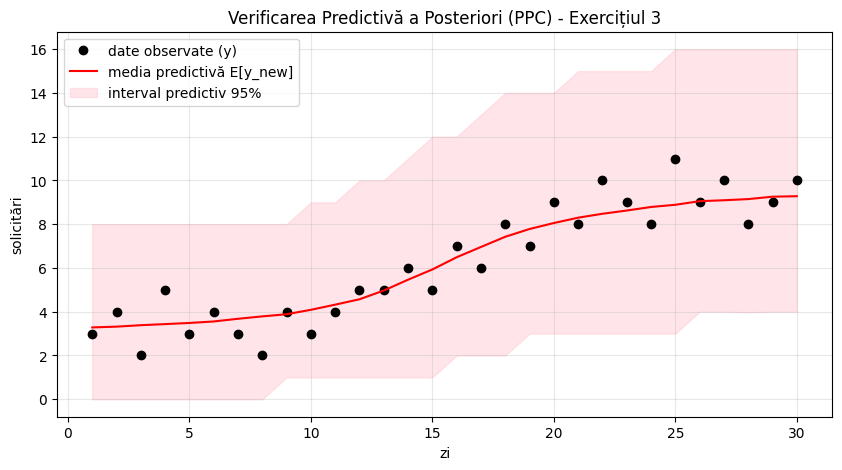

Puncte observate în intervalul predictiv 95%: 1.0


In [29]:
with m3:
    pm.sample_posterior_predictive(idata3, extend_inferencedata=True, random_seed=SEED)

ppc = idata3.posterior_predictive["obs"].values.reshape(-1, 30)
ppc_mean = ppc.mean(axis=0)
ppc_lo, ppc_hi = np.percentile(ppc, [2.5, 97.5], axis=0)

plt.figure(figsize=(10, 5))
plt.plot(t, y, "ko", label="date observate (y)")
plt.plot(t, ppc_mean, "r-", label="media predictivă E[y_new]")
plt.fill_between(t, ppc_lo, ppc_hi, color="pink", alpha=0.4, label="interval predictiv 95%")
plt.xlabel("zi")
plt.ylabel("solicitări")
plt.title("Verificarea Predictivă a Posteriori (PPC) - Exercițiul 3")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig("img/ex3_ppc.png", dpi=150)
plt.show()
print("Puncte observate în intervalul predictiv 95%:", ((y >= ppc_lo) & (y <= ppc_hi)).mean())